In [1]:
%pip install pandas numpy matplotlib scikit-learn openpyxl python-calamine joblib

   ---------------------------------------- 0.0/782.4 kB ? eta -:--:--
   ------------- -------------------------- 262.1/782.4 kB ? eta -:--:--
   ---------------------------------------- 782.4/782.4 kB 3.9 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\Admin\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [2]:


from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [4]:
import pandas as pd

df = pd.read_excel(
    r"C:\Users\Admin\Downloads\solar energy generation data.xlsx",
    nrows=100000
)

print(df.shape)
df.head()

(100000, 13)


,timestamp,Active_Energy_Delivered_Received,Current_Phase_Average,Active_Power,Wind_Speed,Weather_Temperature_Celsius,Weather_Relative_Humidity,Global_Horizontal_Radiation,Diffuse_Horizontal_Radiation,Wind_Direction,Weather_Daily_Rainfall,Radiation_Global_Tilted,Radiation_Diffuse_Tilted
0,2013-07-25 16:35:00,229529.0,43.305336,10.486401,2.627454,18.406675,24.903791,298.341827,34.613453,149.991760,0.0,432.994080,40.610329
1,2013-07-25 16:40:00,229531.0,42.345665,10.244035,3.660713,18.284193,25.291599,280.379059,34.562992,122.356659,0.0,410.407257,39.991482
2,2013-07-25 16:45:00,229531.0,41.597000,10.061766,3.340475,18.285887,25.120466,260.622040,34.435699,107.599136,0.0,391.104370,41.219341
3,2013-07-25 16:50:00,229533.0,40.403664,9.764899,4.227108,18.181446,24.905891,241.102402,34.093025,128.635834,0.0,368.769440,39.018028
4,2013-07-25 16:55:00,229533.0,38.938004,9.405300,2.616484,18.126253,25.161659,220.811844,32.202251,135.611786,0.0,347.886505,37.326550


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column                            Non-Null Count   Dtype         
---  ------                            --------------   -----         
 0   timestamp                         100000 non-null  datetime64[ns]
 1   Active_Energy_Delivered_Received  99979 non-null   float64       
 2   Current_Phase_Average             99976 non-null   float64       
 3   Active_Power                      99976 non-null   float64       
 4   Wind_Speed                        99979 non-null   float64       
 5   Weather_Temperature_Celsius       99976 non-null   float64       
 6   Weather_Relative_Humidity         99976 non-null   float64       
 7   Global_Horizontal_Radiation       99976 non-null   float64       
 8   Diffuse_Horizontal_Radiation      99976 non-null   float64       
 9   Wind_Direction                    99979 non-null   float64       
 10  Weather_Daily_Rainfall           

In [6]:
df.isnull().sum()

timestamp                              0
Active_Energy_Delivered_Received      21
Current_Phase_Average                 24
Active_Power                          24
Wind_Speed                            21
Weather_Temperature_Celsius           24
Weather_Relative_Humidity             24
Global_Horizontal_Radiation           24
Diffuse_Horizontal_Radiation          24
Wind_Direction                        21
Weather_Daily_Rainfall                21
Radiation_Global_Tilted             9238
Radiation_Diffuse_Tilted            9238
dtype: int64

In [7]:
missing = df.isnull().sum()

missing_percent = (missing / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage": missing_percent.round(2)
})

display(missing_table)

,Missing Values,Missing Percentage
timestamp,0,0.00
Active_Energy_Delivered_Received,21,0.02
Current_Phase_Average,24,0.02
Active_Power,24,0.02
Wind_Speed,21,0.02
Weather_Temperature_Celsius,24,0.02
Weather_Relative_Humidity,24,0.02
Global_Horizontal_Radiation,24,0.02
Diffuse_Horizontal_Radiation,24,0.02
Wind_Direction,21,0.02


In [8]:
df = df.drop(columns=[
    "Radiation_Global_Tilted",
    "Radiation_Diffuse_Tilted"
])

In [9]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

df = df.sort_values("timestamp")

df = df.drop_duplicates(subset="timestamp")

df = df.dropna(subset=["timestamp", "Active_Power"])

df = df.ffill()

In [10]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

df.head()

Dataset shape: (99976, 11)

Missing values:
timestamp                           0
Active_Energy_Delivered_Received    0
Current_Phase_Average               0
Active_Power                        0
Wind_Speed                          0
Weather_Temperature_Celsius         0
Weather_Relative_Humidity           0
Global_Horizontal_Radiation         0
Diffuse_Horizontal_Radiation        0
Wind_Direction                      0
Weather_Daily_Rainfall              0
dtype: int64


,timestamp,Active_Energy_Delivered_Received,Current_Phase_Average,Active_Power,Wind_Speed,Weather_Temperature_Celsius,Weather_Relative_Humidity,Global_Horizontal_Radiation,Diffuse_Horizontal_Radiation,Wind_Direction,Weather_Daily_Rainfall
0,2013-07-25 16:35:00,229529.0,43.305336,10.486401,2.627454,18.406675,24.903791,298.341827,34.613453,149.991760,0.0
1,2013-07-25 16:40:00,229531.0,42.345665,10.244035,3.660713,18.284193,25.291599,280.379059,34.562992,122.356659,0.0
2,2013-07-25 16:45:00,229531.0,41.597000,10.061766,3.340475,18.285887,25.120466,260.622040,34.435699,107.599136,0.0
3,2013-07-25 16:50:00,229533.0,40.403664,9.764899,4.227108,18.181446,24.905891,241.102402,34.093025,128.635834,0.0
4,2013-07-25 16:55:00,229533.0,38.938004,9.405300,2.616484,18.126253,25.161659,220.811844,32.202251,135.611786,0.0


In [11]:
print("Duplicate timestamps:", df["timestamp"].duplicated().sum())
print("Missing power values:", df["Active_Power"].isnull().sum())
print("Start date:", df["timestamp"].min())
print("End date:", df["timestamp"].max())

Duplicate timestamps: 0
Missing power values: 0
Start date: 2013-07-25 16:35:00
End date: 2014-07-07 23:05:00


In [14]:
%pip install python-calamine

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\Admin\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [15]:
import pandas as pd

file_path = r"C:\Users\Admin\Downloads\solar energy generation data.xlsx"

df = pd.read_excel(
    file_path,
    engine="calamine",
    skiprows=range(1, 948576),
    nrows=100000
)

print(df.shape)
display(df.head())

(100000, 13)


,timestamp,Active_Energy_Delivered_Received,Current_Phase_Average,Active_Power,Wind_Speed,Weather_Temperature_Celsius,Weather_Relative_Humidity,Global_Horizontal_Radiation,Diffuse_Horizontal_Radiation,Wind_Direction,Weather_Daily_Rainfall,Radiation_Global_Tilted,Radiation_Diffuse_Tilted
0,2022-09-03 13:05:00,584704.0,57.429333,14.095201,NaN,17.696144,33.093758,1009.821960,89.847984,15.133585,0.0,1117.021851,83.424210
1,2022-09-03 13:10:00,584705.0,56.732670,13.921133,NaN,18.261683,32.154942,1003.522827,88.122932,15.136492,0.0,1111.591187,82.835213
2,2022-09-03 13:15:00,584707.0,56.597992,13.900600,NaN,18.133673,32.108757,1001.439941,91.150063,15.232861,0.0,1106.394165,83.287498
3,2022-09-03 13:20:00,584707.0,56.580006,13.885799,NaN,18.359091,31.321329,993.323730,87.273560,15.387991,0.0,1103.369019,84.848953
4,2022-09-03 13:25:00,584708.0,57.030663,13.996401,NaN,17.945747,31.020838,993.836182,92.030434,15.471824,0.0,1101.278564,88.337837


In [17]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\Admin\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [18]:
from openpyxl import load_workbook
from collections import deque
import pandas as pd

file_path = r"C:\Users\Admin\Downloads\solar energy generation data.xlsx"

workbook = load_workbook(file_path, read_only=True, data_only=True)
sheet = workbook.active

rows = deque(sheet.iter_rows(values_only=True), maxlen=100001)

data = list(rows)
columns = data[0]
df = pd.DataFrame(data[1:], columns=columns)

workbook.close()

print(df.shape)
display(df.head())

(100000, 13)


,2022-09-03 13:00:00,584702,57.559334,14.124399,None,17.683863,33.150192,1014.097961,87.950027,15.15367,0,1123.478882,84.935318
0,2022-09-03 13:05:00,584704.0,57.429333,14.095201,None,17.696144,33.093758,1009.821960,89.847984,15.133585,0.0,1117.021851,83.424210
1,2022-09-03 13:10:00,584705.0,56.732670,13.921133,None,18.261683,32.154942,1003.522827,88.122932,15.136492,0.0,1111.591187,82.835213
2,2022-09-03 13:15:00,584707.0,56.597992,13.900600,None,18.133673,32.108757,1001.439941,91.150063,15.232861,0.0,1106.394165,83.287498
3,2022-09-03 13:20:00,584707.0,56.580006,13.885799,None,18.359091,31.321329,993.323730,87.273560,15.387991,0.0,1103.369019,84.848953
4,2022-09-03 13:25:00,584708.0,57.030663,13.996401,None,17.945747,31.020838,993.836182,92.030434,15.471824,0.0,1101.278564,88.337837


In [19]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDate range:")
print(df["timestamp"].min())
print(df["timestamp"].max())

Shape: (100000, 13)

Columns:
[datetime.datetime(2022, 9, 3, 13, 0), 584702, 57.55933380127, 14.124399185181, None, 17.683862686157, 33.150192260742, 1014.0979614258, 87.95002746582, 15.153670310974, 0, 1123.4788818359, 84.935317993164]

Missing values:
2022-09-03 13:00:00         0
584702                     13
57.559334                  13
14.124399                  13
None                   100000
17.683863                   9
33.150192                   9
1014.097961                 9
87.950027                   9
15.15367                    9
0                           9
1123.478882              1816
84.935318                1816
dtype: int64

Date range:


KeyError: 'timestamp'

In [20]:
df.columns = [
    "timestamp",
    "Active_Energy_Delivered_Received",
    "Current_Phase_Average",
    "Active_Power",
    "Wind_Speed",
    "Weather_Temperature_Celsius",
    "Weather_Relative_Humidity",
    "Global_Horizontal_Radiation",
    "Diffuse_Horizontal_Radiation",
    "Wind_Direction",
    "Weather_Daily_Rainfall",
    "Radiation_Global_Tilted",
    "Radiation_Diffuse_Tilted"
]

print(df.head())
print(df.shape)

            timestamp  Active_Energy_Delivered_Received  \
0 2022-09-03 13:05:00                          584704.0   
1 2022-09-03 13:10:00                          584705.0   
2 2022-09-03 13:15:00                          584707.0   
3 2022-09-03 13:20:00                          584707.0   
4 2022-09-03 13:25:00                          584708.0   

   Current_Phase_Average  Active_Power Wind_Speed  \
0              57.429333     14.095201       None   
1              56.732670     13.921133       None   
2              56.597992     13.900600       None   
3              56.580006     13.885799       None   
4              57.030663     13.996401       None   

   Weather_Temperature_Celsius  Weather_Relative_Humidity  \
0                    17.696144                  33.093758   
1                    18.261683                  32.154942   
2                    18.133673                  32.108757   
3                    18.359091                  31.321329   
4                    

In [21]:
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

print("Start date:", df["timestamp"].min())
print("End date:", df["timestamp"].max())

print("\nMissing values:")
print(df.isnull().sum())

Start date: 2022-09-03 13:05:00
End date: 2023-08-24 07:05:00

Missing values:
timestamp                                0
Active_Energy_Delivered_Received        13
Current_Phase_Average                   13
Active_Power                            13
Wind_Speed                          100000
Weather_Temperature_Celsius              9
Weather_Relative_Humidity                9
Global_Horizontal_Radiation              9
Diffuse_Horizontal_Radiation             9
Wind_Direction                           9
Weather_Daily_Rainfall                   9
Radiation_Global_Tilted               1816
Radiation_Diffuse_Tilted              1816
dtype: int64


In [22]:
df = df.drop(columns=[
    "Wind_Speed",
    "Radiation_Global_Tilted",
    "Radiation_Diffuse_Tilted"
], errors="ignore")

df = df.dropna(subset=["timestamp", "Active_Power"])

df = df.sort_values("timestamp")
df = df.drop_duplicates(subset="timestamp")

df = df.ffill()

print("Shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

Shape: (99987, 10)

Missing values:
timestamp                           0
Active_Energy_Delivered_Received    0
Current_Phase_Average               0
Active_Power                        0
Weather_Temperature_Celsius         0
Weather_Relative_Humidity           0
Global_Horizontal_Radiation         0
Diffuse_Horizontal_Radiation        0
Wind_Direction                      0
Weather_Daily_Rainfall              0
dtype: int64


In [24]:
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.set_index("timestamp")

hourly = df.resample("h").mean(numeric_only=True)

print("Hourly data shape:", hourly.shape)
display(hourly.head())

Hourly data shape: (8515, 9)


,Active_Energy_Delivered_Received,Current_Phase_Average,Active_Power,Weather_Temperature_Celsius,Weather_Relative_Humidity,Global_Horizontal_Radiation,Diffuse_Horizontal_Radiation,Wind_Direction,Weather_Daily_Rainfall
timestamp,,,,,,,,,
2022-09-03 13:00:00,584709.727273,56.196424,13.786443,18.114999,31.286119,976.345215,87.326585,15.405099,0.0
2022-09-03 14:00:00,584722.250000,51.205612,12.534861,18.647229,29.851457,848.401393,74.440614,15.781709,0.0
2022-09-03 15:00:00,584733.666667,42.238500,10.312984,18.842021,28.649542,660.339111,63.557367,15.869031,0.0
2022-09-03 16:00:00,584742.250000,29.094056,7.067784,18.433083,28.075007,438.138000,53.792281,17.682716,0.0
2022-09-03 17:00:00,584747.250000,12.153167,2.805244,17.430479,29.680730,150.737149,42.791140,19.625463,0.0


In [25]:
data = hourly.copy()

data["power_lag_1"] = data["Active_Power"]
data["power_lag_2"] = data["Active_Power"].shift(1)
data["power_lag_3"] = data["Active_Power"].shift(2)

data["hour"] = data.index.hour
data["month"] = data.index.month

data["target"] = data["Active_Power"].shift(-1)

data = data.dropna()

print("Model data shape:", data.shape)
display(data.head())

Model data shape: (8322, 15)


,Active_Energy_Delivered_Received,Current_Phase_Average,Active_Power,Weather_Temperature_Celsius,Weather_Relative_Humidity,Global_Horizontal_Radiation,Diffuse_Horizontal_Radiation,Wind_Direction,Weather_Daily_Rainfall,power_lag_1,power_lag_2,power_lag_3,hour,month,target
timestamp,,,,,,,,,,,,,,,
2022-09-03 15:00:00,584733.666667,42.238500,10.312984,18.842021,28.649542,660.339111,63.557367,15.869031,0.0,10.312984,12.534861,13.786443,15,9,7.067784
2022-09-03 16:00:00,584742.250000,29.094056,7.067784,18.433083,28.075007,438.138000,53.792281,17.682716,0.0,7.067784,10.312984,12.534861,16,9,2.805244
2022-09-03 17:00:00,584747.250000,12.153167,2.805244,17.430479,29.680730,150.737149,42.791140,19.625463,0.0,2.805244,7.067784,10.312984,17,9,0.082611
2022-09-03 18:00:00,584748.000000,2.101111,0.082611,15.723763,35.138336,10.892422,8.676705,19.084611,0.0,0.082611,2.805244,7.067784,18,9,0.000000
2022-09-03 19:00:00,584748.000000,0.800000,0.000000,14.053976,41.196835,3.450698,1.754970,17.527383,0.0,0.000000,0.082611,2.805244,19,9,0.000000


In [26]:
print("Missing values:")
print(data.isnull().sum())

print("Hourly time range:", hourly.index.min(), "to", hourly.index.max())

Missing values:
Active_Energy_Delivered_Received    0
Current_Phase_Average               0
Active_Power                        0
Weather_Temperature_Celsius         0
Weather_Relative_Humidity           0
Global_Horizontal_Radiation         0
Diffuse_Horizontal_Radiation        0
Wind_Direction                      0
Weather_Daily_Rainfall              0
power_lag_1                         0
power_lag_2                         0
power_lag_3                         0
hour                                0
month                               0
target                              0
dtype: int64
Hourly time range: 2022-09-03 13:00:00 to 2023-08-24 07:00:00


In [27]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

X = data.drop(columns=["target", "Active_Power"])
y = data["target"]

split = int(len(data) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 6657
Testing rows: 1665


In [28]:
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [29]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 3))

MAE: 0.258
RMSE: 0.615
R2 Score: 0.978


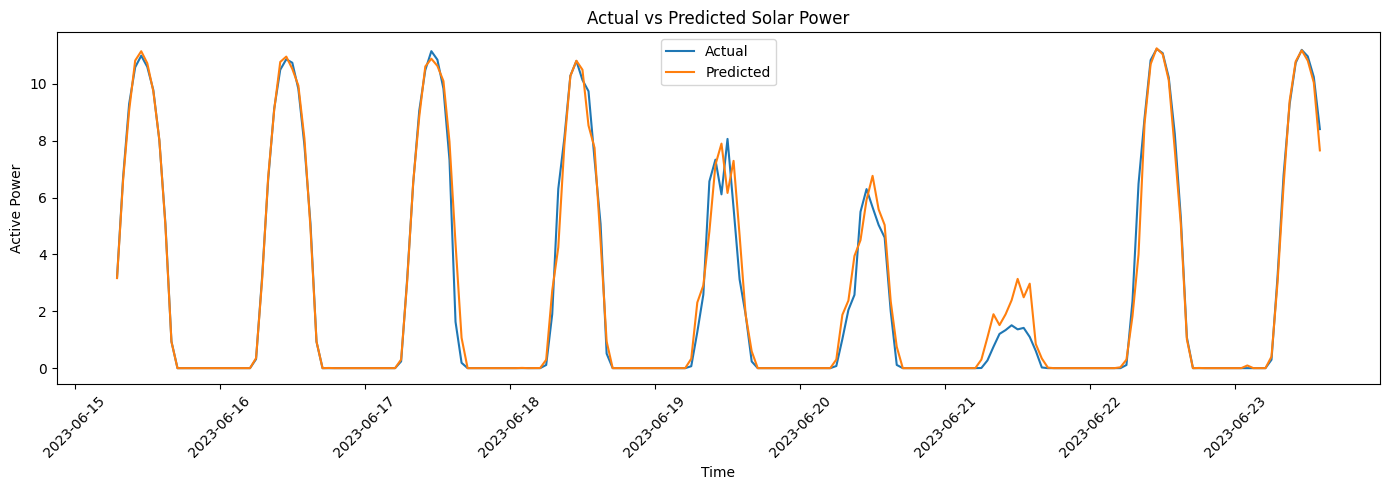

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(y_test.index[:200], y_test.iloc[:200], label="Actual")
plt.plot(y_test.index[:200], y_pred[:200], label="Predicted")
plt.xlabel("Time")
plt.ylabel("Active Power")
plt.title("Actual vs Predicted Solar Power")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [31]:
from sklearn.metrics import r2_score

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

train_accuracy = r2_score(y_train, y_train_pred)
test_accuracy = r2_score(y_test, y_test_pred)

print("Training R2 Score:", round(train_accuracy * 100, 2), "%")
print("Testing R2 Score:", round(test_accuracy * 100, 2), "%")

Training R2 Score: 99.65 %
Testing R2 Score: 97.85 %


In [32]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\Admin\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [33]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42
)

xgb_model.fit(X_train, y_train)

y_train_pred = xgb_model.predict(X_train)
y_test_pred = xgb_model.predict(X_test)

In [34]:
from sklearn.metrics import r2_score

train_score = r2_score(y_train, y_train_pred)
test_score = r2_score(y_test, y_test_pred)

print("XGBoost Training R2 Score:", round(train_score * 100, 2), "%")
print("XGBoost Testing R2 Score:", round(test_score * 100, 2), "%")

XGBoost Training R2 Score: 98.89 %
XGBoost Testing R2 Score: 97.97 %
